In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path
from matplotlib.colors import Normalize
from matplotlib import cm
device = "cuda" if torch.cuda.is_available() else "cpu"

We start with the VDP oscillator.

In [2]:
def vanderpol_vec_torch(x, mu=1.0):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    if not torch.is_tensor(mu):
        mu = x.new_tensor(mu)
    else:
        mu = mu.to(dtype=x.dtype, device=x.device)

    x0 = x[:, 0]   # x
    x1 = x[:, 1]   # y

    f0 = x1
    f1 = -x0 + mu * x1 * (1 - x0 * x0)

    out = torch.stack([f0, f1], dim=1)  # (B,2)

    if is_1d:
        return out[0]
    return out

nu = 0.25

In [3]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8):
        super().__init__()
        self.Gamma = nn.Linear(2, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, 2, bias= False)
        self.I_s = nn.Parameter(torch.zeros(2))
        self.B_s = nn.Parameter(torch.randn(2, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [4]:
latent_dim = 64
model = TwoLayerMLP(latent_dim).to(device)

opt = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

n_samples = 25_000
x_train = (torch.rand(n_samples, 2) * 8.0 - 4.0).to(device)
y_train = vanderpol_vec_torch(x_train).to(device)
_eye2 = torch.eye(2, device=device)
D_target = (nu**2) * _eye2  

lambda_diff = 20
epochs = 30_000

for epoch in trange(epochs, desc= 'training MLP'):
    opt.zero_grad()
    
    
    pred = model(x_train)
    
    drift_loss = loss_fn(pred, y_train)

    D_model = model.B_s@(model.B_s.T)
    diffusion_loss = torch.norm(D_model - D_target, p='fro')**2
    
    loss = drift_loss + lambda_diff*diffusion_loss
    loss.backward()
    opt.step()
    
    if (epoch + 1) % 1000 == 0:
        print(f"epoch {epoch+1:4d} loss: {loss.item():.6f} drift: {drift_loss:.6f} diff: {diffusion_loss:.6f}")

training MLP:   4%|▊                      | 1056/30000 [00:03<01:43, 280.57it/s]

epoch 1000 loss: 167.896103 drift: 22.507608 diff: 7.269424


training MLP:   7%|█▌                     | 2049/30000 [00:07<01:53, 246.94it/s]

epoch 2000 loss: 39.551704 drift: 11.264750 diff: 1.414348


training MLP:  10%|██▎                    | 3030/30000 [00:11<01:39, 271.56it/s]

epoch 3000 loss: 13.498430 drift: 6.173697 diff: 0.366237


... (50 outputs left out)

training MLP:  97%|█████████████████████▎| 29044/30000 [01:42<00:03, 295.04it/s]

epoch 29000 loss: 0.000325 drift: 0.000325 diff: 0.000000


training MLP: 100%|██████████████████████| 30000/30000 [01:45<00:00, 284.77it/s]

epoch 30000 loss: 0.000281 drift: 0.000281 diff: 0.000000


In [5]:
print(model.B_s@(model.B_s.T))

Gamma = model.Gamma.weight.detach()
Gamma_pinv = torch.linalg.pinv(Gamma).detach()
b = model.input_bias.detach()
W = Gamma @ model.W_s.weight.detach() 
I = Gamma @ model.I_s.detach() +  b
B = Gamma @ model.B_s.detach()

print(Gamma_pinv@Gamma)

tensor([[ 6.2501e-02, -7.8266e-08],
        [-7.8266e-08,  6.2500e-02]], grad_fn=<MmBackward0>)
tensor([[1.0000e+00, 1.4901e-08],
        [6.7055e-08, 1.0000e+00]])


In [6]:
def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

In [7]:
y0 = torch.tensor([-2.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.01; T = 400; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|██████████████████████████████████| 39999/39999 [00:00<00:00, 57360.06it/s]


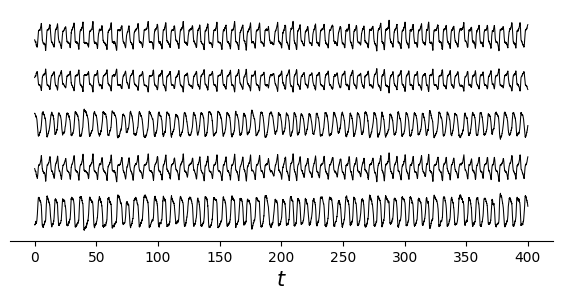

In [16]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(7,3)

t = np.linspace(0,T,Nt)

ds = 5
num_vis_neurons = 5
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace = u[v, ::ds] + 10*n - torch.mean(u[v, :])
    ax.plot(t[::ds],trace, 'black', linewidth = 0.75)
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)
ax.set_xlabel(r'$t$',fontsize=15)
plt.show()

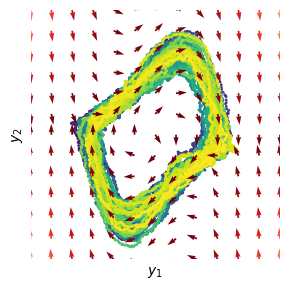

In [9]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(3,3)

grid_lim = 8; grid_res = 25
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

time = np.linspace(0,T,int(T/dt))
ds = 1
ax.scatter(y[0,::ds], y[1,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_model = model(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
U_t = F_model[:,0].reshape(grid_res,grid_res).numpy()
V_t = F_model[:,1].reshape(grid_res,grid_res).numpy()

mag = np.sqrt(U_t**2 + V_t**2)

safe_mag = np.where(mag == 0, 1.0, mag)

Ux_unit = U_t / safe_mag
Vy_unit = V_t / safe_mag

arrow_length = 0.35
U_plot = Ux_unit * arrow_length
V_plot = Vy_unit * arrow_length

norm = Normalize(vmin=mag.min(), vmax=mag.max())
Q = ax.quiver(
    Xn, Yn,
    U_plot, V_plot,
    mag,                     
    cmap='Reds_r',
    norm=norm,
    angles='xy',
    scale_units='xy',
    scale=1.0,               
    width=0.007,
    headwidth=3,
    headlength=5,
    minlength=0
)

ax.set_aspect('equal')
ax.set_xlim([-4,4])
ax.set_ylim([-4,4])

ax.set_xlabel(r'$y_1$', fontsize = 10)
ax.set_ylabel(r'$y_2$', fontsize = 10)

ax.set_xticks([])
ax.set_yticks([])
sns.despine(left=True, bottom = True)
plt.tight_layout()

plt.show()

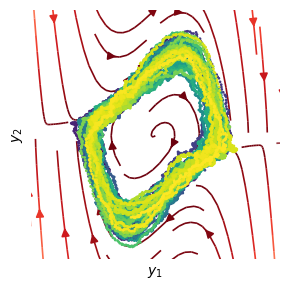

In [15]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(3,3)

grid_lim = 8; grid_res = 25
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

time = np.linspace(0,T,int(T/dt))
ds = 1
ax.scatter(y[0,::ds], y[1,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_model = model(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
U_t = F_model[:,0].reshape(grid_res,grid_res).numpy()
V_t = F_model[:,1].reshape(grid_res,grid_res).numpy()

mag = np.sqrt(U_t**2 + V_t**2)
norm = Normalize(vmin=mag.min(), vmax=mag.max())

strm = ax.streamplot(
    Xn, Yn, 
    U_t, V_t, 
    color=mag,           
    cmap='Reds_r', 
    norm=norm,
    density=1,         
    linewidth=1.2,       
    arrowsize=1.2,
    zorder = -100
)

ax.set_aspect('equal')
ax.set_xlim([-4,4])
ax.set_ylim([-4,4])

ax.set_xlabel(r'$y_1$', fontsize=10)
ax.set_ylabel(r'$y_2$', fontsize=10)

ax.set_xticks([])
ax.set_yticks([])
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()

Now we will do the Lorenz attractor.

In [133]:
params = torch.load('lorenz_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

def lorenz_vec_torch(x, sigma = 10, rho = 28, beta = 8/3):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    x0 = x[:, 0]   # x
    x1 = x[:, 1]   # y
    x2 = x[:, 2]   # z

    f0 = sigma*(x1 - x0)
    f1 = x0*(rho-x2)-x1
    f2 = x0*x1 - beta*x2

    out = torch.stack([f0, f1, f2], dim=1)  # (B,2)

    if is_1d:
        return out[0]
    return out

In [128]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8, proj_dim = 2):
        super().__init__()
        self.Gamma = nn.Linear(proj_dim, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, proj_dim, bias= False)
        self.I_s = nn.Parameter(torch.zeros(proj_dim))
        self.B_s = nn.Parameter(torch.randn(proj_dim, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [148]:
latent_dim = 512
model = TwoLayerMLP(latent_dim, proj_dim = 3).to(device)

params = torch.load('lorenz_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

In [149]:
with torch.no_grad():
    model.Gamma.weight.copy_(Gamma)
    model.W_s.weight.copy_(Gamma_pinv@W)
    model.I_s.copy_(Gamma_pinv@(I-b))
    model.B_s.copy_(Gamma_pinv@B)
    model.input_bias.copy_(b)

In [130]:
def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

In [131]:
y0 = torch.tensor([0.0, 0.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.0001; T = 100; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 999999/999999 [00:35<00:00, 28184.29it/s]


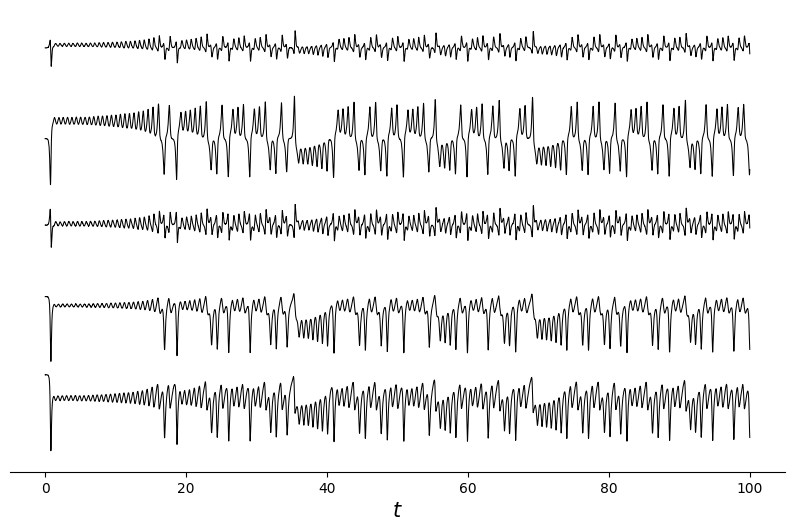

In [117]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(10,6)

t = np.linspace(0,T,Nt)

ds = 10
num_vis_neurons = 5
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace = u[v, 100::ds] + 10*n - torch.mean(u[v, :])
    ax.plot(t[100::ds],trace, 'black', linewidth = 0.75)

ax.set_xlabel(r'$t$', fontsize = 15)
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_95459/3801362570.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


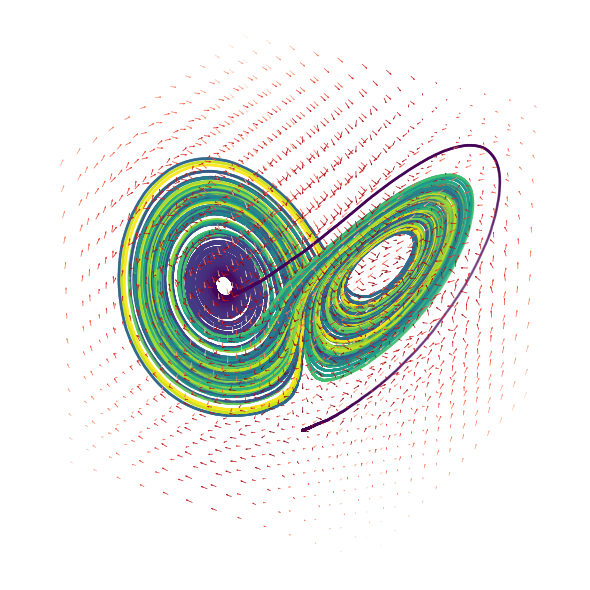

In [151]:
grid_lim = 25
grid_res = 25
arrow_length = 1.0   
subsample = 2         
cmap_name = 'Reds_r'

xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
zs = torch.linspace(0, 50, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
pts = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

with torch.no_grad():
    F = model(pts).cpu().numpy()   

U = F[:, 0].reshape(grid_res, grid_res, grid_res)
V = F[:, 1].reshape(grid_res, grid_res, grid_res)
W = F[:, 2].reshape(grid_res, grid_res, grid_res)

Xn = X.numpy(); Yn = Y.numpy(); Zn = Z.numpy()

mag = np.sqrt(U**2 + V**2 + W**2)

safe_mag = np.where(mag == 0, 1.0, mag)
U_unit = U / safe_mag
V_unit = V / safe_mag
W_unit = W / safe_mag

U_plot = U_unit * arrow_length
V_plot = V_unit * arrow_length
W_plot = W_unit * arrow_length

s = subsample
Xs = Xn[::s, ::s, ::s].flatten()
Ys = Yn[::s, ::s, ::s].flatten()
Zs = Zn[::s, ::s, ::s].flatten()

Us = U_plot[::s, ::s, ::s].flatten()
Vs = V_plot[::s, ::s, ::s].flatten()
Ws = W_plot[::s, ::s, ::s].flatten()

Mags = mag[::s, ::s, ::s].flatten()

norm = Normalize(vmin=Mags.min(), vmax=Mags.max())
cmap = cm.get_cmap(cmap_name)
colors = cmap(norm(Mags))

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111, projection='3d')

ax.quiver(Xs, Ys, Zs, Us, Vs, Ws, length=1.0, normalize=False, colors=colors, linewidths=0.5)
ax.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True)

ax.set_xlim(-grid_lim, grid_lim)
ax.set_ylim(-grid_lim, grid_lim)
ax.set_zlim(zs.min(), zs.max())

ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_box_aspect((2*grid_lim, 2*grid_lim, zs.max()-zs.min()))

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.set_axis_off()          
ax.grid(False) 

sns.despine()
plt.tight_layout()
plt.show()

# Dadras attractor

In [152]:
latent_dim = 1024
model = TwoLayerMLP(latent_dim, proj_dim = 3).to(device)

params = torch.load('dadras_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

with torch.no_grad():
    model.Gamma.weight.copy_(Gamma)
    model.W_s.weight.copy_(Gamma_pinv@W)
    model.I_s.copy_(Gamma_pinv@(I-b))
    model.B_s.copy_(Gamma_pinv@B)
    model.input_bias.copy_(b)

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_95459/1271835202.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  W = torch.tensor(params['W'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_95459/1271835202.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma = torch.tensor(params['Gamma'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_95459/1271835202.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  I = torch.tensor(params['I'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_954

In [153]:
y0 = torch.tensor([1.0, 1.0, 0.0], dtype=torch.float32)

dt = 0.0001; T = 100; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 999999/999999 [00:59<00:00, 16818.78it/s]


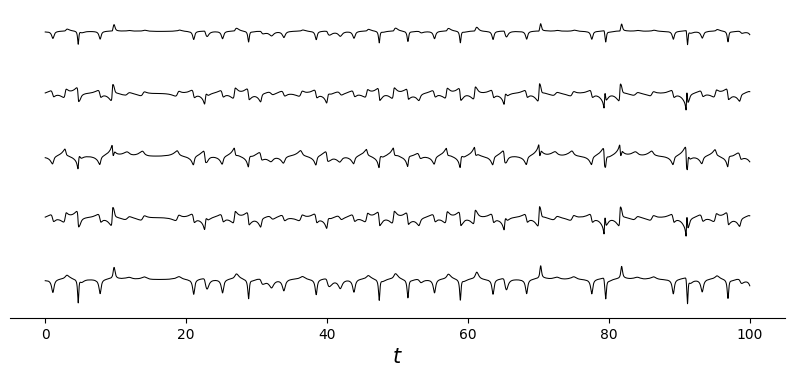

In [165]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(10,4)

t = np.linspace(0,T,Nt)

ds = 10
num_vis_neurons = 5
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace = u[v, 100::ds] + 7.5*n - torch.mean(u[v, :])
    ax.plot(t[100::ds],trace, 'black', linewidth = 0.75)

ax.set_xlabel(r'$t$', fontsize = 15)
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)

plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_95459/182925526.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


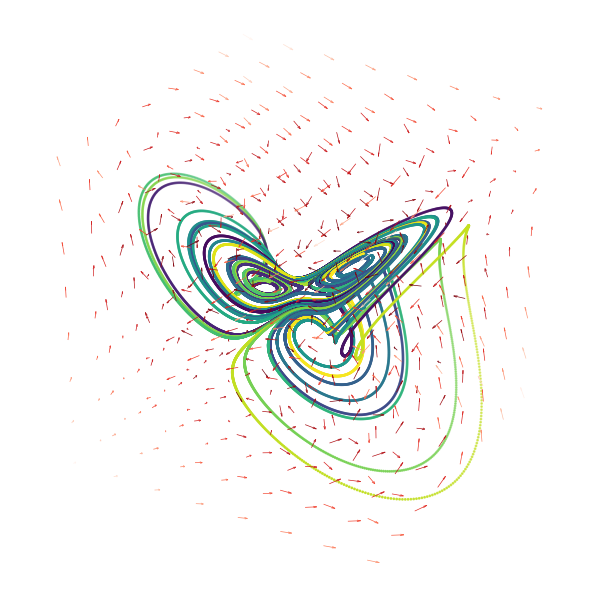

In [170]:
grid_lim = 15
grid_res = 15
arrow_length = 1.0   
subsample = 2         
cmap_name = 'Reds_r'

xs = torch.linspace(-15, 15, grid_res)
ys = torch.linspace(-10, 10, grid_res)
zs = torch.linspace(-15, 15, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
pts = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

with torch.no_grad():
    F = model(pts).cpu().numpy()   

U = F[:, 0].reshape(grid_res, grid_res, grid_res)
V = F[:, 1].reshape(grid_res, grid_res, grid_res)
W = F[:, 2].reshape(grid_res, grid_res, grid_res)

Xn = X.numpy(); Yn = Y.numpy(); Zn = Z.numpy()

mag = np.sqrt(U**2 + V**2 + W**2)

safe_mag = np.where(mag == 0, 1.0, mag)
U_unit = U / safe_mag
V_unit = V / safe_mag
W_unit = W / safe_mag

U_plot = U_unit * arrow_length
V_plot = V_unit * arrow_length
W_plot = W_unit * arrow_length

s = subsample
Xs = Xn[::s, ::s, ::s].flatten()
Ys = Yn[::s, ::s, ::s].flatten()
Zs = Zn[::s, ::s, ::s].flatten()

Us = U_plot[::s, ::s, ::s].flatten()
Vs = V_plot[::s, ::s, ::s].flatten()
Ws = W_plot[::s, ::s, ::s].flatten()

Mags = mag[::s, ::s, ::s].flatten()

norm = Normalize(vmin=Mags.min(), vmax=Mags.max())
cmap = cm.get_cmap(cmap_name)
colors = cmap(norm(Mags))

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111, projection='3d')

ax.quiver(Xs, Ys, Zs, Us, Vs, Ws, length=1.0, normalize=False, colors=colors, linewidths=0.5)
ax.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True)

ax.set_xlim(-15, 15)
ax.set_ylim(-10, 10)
ax.set_zlim(-15, 15)

ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_box_aspect((2*grid_lim, 2*grid_lim, zs.max()-zs.min()))

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.set_axis_off()          
ax.grid(False) 

sns.despine()

plt.tight_layout()
plt.show()